# Analyse exploratoire

Cible : `TotalKg`, le total réalisé en compétition (squat + développé couché + soulevé de terre).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme()

In [2]:
train = pd.read_csv("../data/train.csv")
test = pd.read_csv("../data/test.csv")

TARGET = "TotalKg"
NUM_COLS = ["Age", "BodyweightKg", "MeetYear"]
CAT_COLS = [c for c in train.columns if c not in NUM_COLS + ["id", TARGET]]
FEATURES = NUM_COLS + CAT_COLS

train.shape, test.shape

((105000, 18), (45000, 17))

In [3]:
train.head()

,id,Age,BodyweightKg,MeetYear,Sex,Equipment,AgeClass,BirthYearClass,WeightClassKg,Tested,Country,State,Federation,ParentFederation,MeetCountry,MeetState,Sanctioned,TotalKg
0,27822,16.5,65.25,2016,M,Single-ply,16-17,14-18,66,Yes,Russia,Unknown,FPR,IPF,Russia,KLU,Yes,500.0
1,85202,27.0,88.50,2022,M,Raw,24-34,24-39,90,Untested,USA,IL,USPA,IPL,USA,IL,Yes,512.5
2,42217,29.5,92.30,2018,F,Raw,24-34,24-39,84+,Yes,USA,MA,USAPL,IPF,USA,MA,Yes,360.0
3,119958,27.0,52.00,2019,F,Single-ply,24-34,24-39,52,Yes,Russia,Unknown,WPC,WPC,Russia,ROS,Yes,362.5
4,37678,52.5,117.50,2025,M,Single-ply,50-54,50-59,125,Yes,USA,MI,USAPL,Unknown,USA,OH,Yes,355.0


In [4]:
train.describe()

,id,Age,BodyweightKg,MeetYear,TotalKg
count,105000.000000,105000.000000,105000.000000,105000.000000,105000.000000
mean,74972.531362,28.537771,83.423773,2017.667495,493.011946
std,43332.026782,12.056412,21.984334,8.013321,171.397819
min,1.000000,0.500000,19.100000,1966.000000,24.000000
25%,37474.750000,19.500000,67.090000,2015.000000,352.500000
50%,74906.500000,25.000000,81.400000,2019.000000,492.500000
75%,112544.250000,34.000000,97.100000,2023.000000,612.500000
max,149999.000000,92.500000,241.800000,2026.000000,1363.050000


In [5]:
train[CAT_COLS].nunique().sort_values()

Tested                2
Sanctioned            2
Sex                   3
Equipment             5
BirthYearClass        8
AgeClass             19
ParentFederation     22
MeetCountry         121
State               122
WeightClassKg       146
Country             149
MeetState           240
Federation          399
dtype: int64

## 1. Valeurs manquantes

Aucun `NaN`, mais des `"Unknown"` :

In [6]:
unknown = (train[CAT_COLS] == "Unknown").mean().mul(100).round(1)
unknown[unknown > 0].sort_values(ascending=False)

State               63.8
MeetState           33.9
ParentFederation    22.3
BirthYearClass       3.1
Country              1.9
WeightClassKg        1.1
dtype: float64

`State` et `MeetState` sont trop incomplètes pour être utiles.

## 2. Âges faux

In [7]:
train[train.Age < 8][["Age", "Sex", "BodyweightKg", "Federation", TARGET]].sort_values("Age")

,Age,Sex,BodyweightKg,Federation,TotalKg
42681,0.5,M,88.10,BAWLA,420.00
19620,0.5,M,90.00,ADFPA,625.00
49873,0.5,M,75.00,APF,727.50
43967,0.5,M,125.00,USPF,578.33
73411,0.5,M,85.00,USAPL,517.50
56641,0.5,M,56.00,USPF,385.55
28317,2.0,M,100.00,USPF,470.00
28825,2.5,M,67.50,NASA,537.50
57015,2.5,M,100.00,CPU,635.00
93177,2.5,M,90.00,WNPF,502.50


Certaines fédérations acceptent des enfants dès 5 ans. Mais un âge de moins de 5 ans, ou de moins de 8 ans
avec un poids d'adulte, est faux : ce sont des adultes d'âge inconnu.

In [8]:
def is_wrong_age(df):
    return (df.Age < 5) | ((df.Age < 8) & (df.BodyweightKg > 50))

is_wrong_age(train).sum(), is_wrong_age(test).sum()

(np.int64(24), np.int64(8))

## 3. Doublons

In [9]:
dup = train[train[FEATURES].duplicated(keep=False)]
same_total = dup.groupby(FEATURES)[TARGET].nunique() == 1

print("Lignes en double :", train[FEATURES].duplicated().sum())
print("Groupes avec exactement le même total :", same_total.mean().round(2))
print("Lignes du test avec un jumeau dans le train :", test[FEATURES].merge(train[FEATURES].drop_duplicates()).shape[0])

Lignes en double : 558
Groupes avec exactement le même total : 0.74
Lignes du test avec un jumeau dans le train : 465


Les doublons ont presque toujours le même total : c'est la même performance enregistrée dans plusieurs
divisions. Il faudra les garder dans le même fold de validation croisée.

## 4. La cible

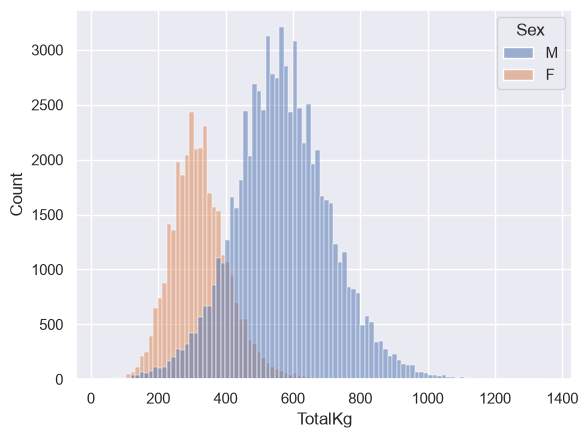

In [10]:
sns.histplot(data=train[train.Sex != "Mx"], x=TARGET, hue="Sex", bins=100)
plt.show()

In [11]:
train.groupby("Sex")[TARGET].describe()

,count,mean,std,min,25%,50%,75%,max
Sex,,,,,,,,
F,32537.0,323.230696,84.814595,55.0,265.0,317.5,372.50,818.00
M,72454.0,569.273321,143.453350,24.0,477.5,565.0,659.98,1363.05
Mx,9.0,352.000000,94.622936,255.0,275.0,332.5,410.00,522.50


Les deux bosses viennent du sexe. Les femmes font ~57 % du total des hommes.

## 5. Variables numériques

In [12]:
def plot_median_by(col, step=1):
    for sex in ["M", "F"]:
        d = train[train.Sex == sex]
        bins = (d[col] // step) * step
        med = d.groupby(bins)[TARGET].median()
        med = med[d.groupby(bins).size() > 30]
        plt.plot(med.index, med.values, label=sex)
    plt.xlabel(col)
    plt.ylabel("TotalKg médian")
    plt.legend()
    plt.show()

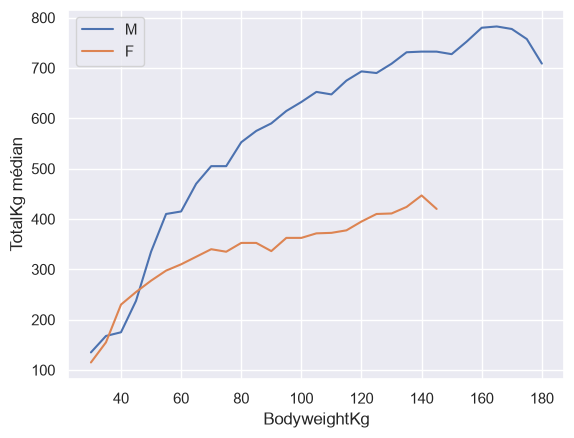

In [13]:
plot_median_by("BodyweightKg", step=5)

Le total augmente avec le poids, de moins en moins vite.

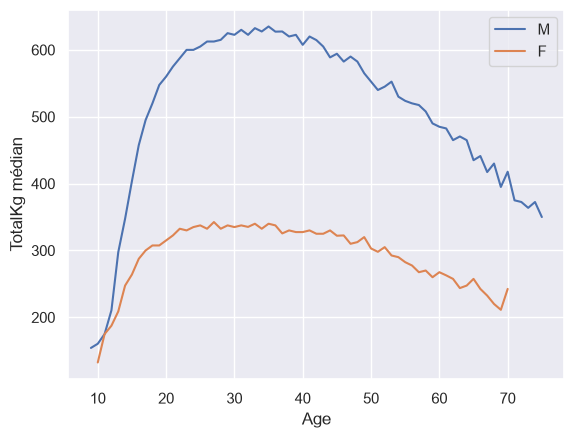

In [14]:
plot_median_by("Age")

Courbe en cloche, avec un pic entre 25 et 35 ans.

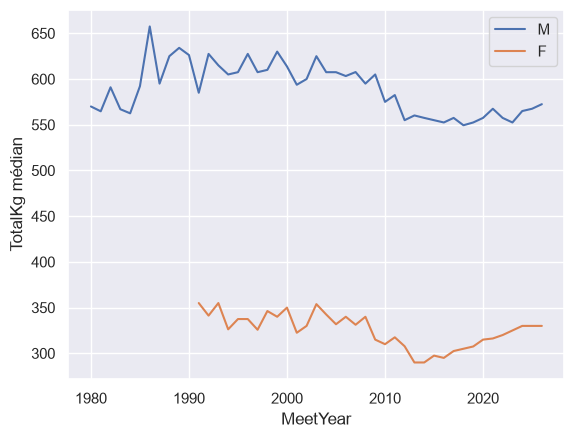

In [15]:
plot_median_by("MeetYear")

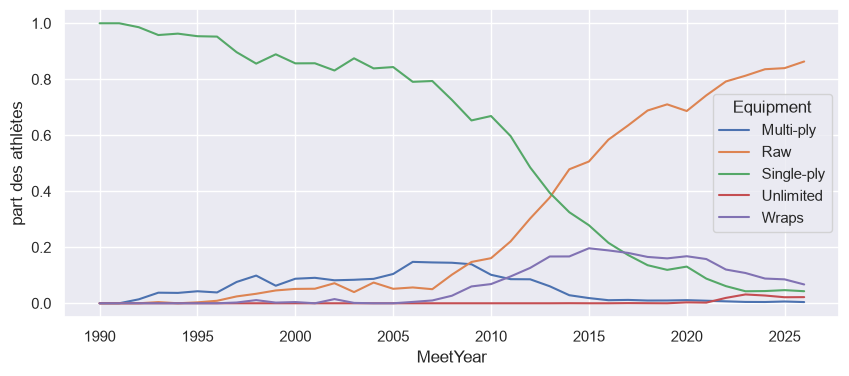

In [16]:
pd.crosstab(train.MeetYear, train.Equipment, normalize="index").loc[1990:].plot(figsize=(10, 4))
plt.ylabel("part des athlètes")
plt.show()

La baisse vers 2010-2015 correspond à l'arrivée massive du Raw : l'effet de l'année est surtout un effet d'équipement.

## 6. Variables catégorielles

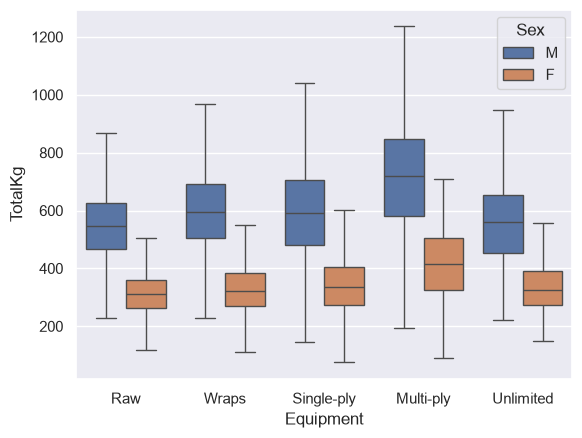

In [17]:
order = ["Raw", "Wraps", "Single-ply", "Multi-ply", "Unlimited"]
sns.boxplot(data=train[train.Sex != "Mx"], x="Equipment", y=TARGET, hue="Sex", order=order, showfliers=False)
plt.show()

`Unlimited` paraît faible parce que ce sont surtout des lycéen·ne·s texan·e·s :

In [18]:
train[train.Equipment == "Unlimited"].Federation.value_counts().head(3)

Federation
THSWPA    503
THSPA     476
IPA        21
Name: count, dtype: int64

In [19]:
train[train.Sex != "Mx"].pivot_table(index="Tested", columns=["Sex", "Equipment"], values=TARGET,
                                     aggfunc="median")[[("F", "Raw"), ("M", "Raw")]]

Sex,F,M
Equipment,Raw,Raw
Tested,,
Untested,310.0,570.0
Yes,312.5,545.0


Les non testés sont plus forts chez les hommes seulement.

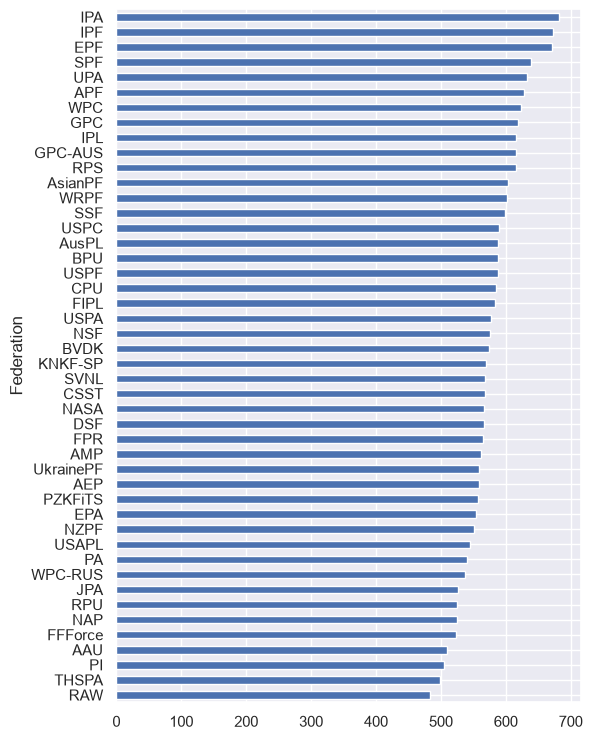

In [20]:
men = train[train.Sex == "M"]
fed = men.groupby("Federation")[TARGET].agg(["count", "mean"])
fed[fed["count"] >= 300].sort_values("mean").plot.barh(y="mean", figsize=(6, 9), legend=False)
plt.show()

In [21]:
for col in ["Federation", "Country"]:
    vc = train[col].value_counts()
    print(f"{col:10s} {len(vc)} modalités, dont {(vc < 20).sum()} avec moins de 20 lignes")

Federation 399 modalités, dont 170 avec moins de 20 lignes
Country    149 modalités, dont 59 avec moins de 20 lignes


Près de 200 kg d'écart entre fédérations, mais beaucoup de modalités rares.

In [22]:
train.Sanctioned.value_counts()

Sanctioned
Yes    104708
No        292
Name: count, dtype: int64

## 7. Variables redondantes

In [23]:
limit = pd.to_numeric(train.WeightClassKg.str.rstrip("+"), errors="coerce")
mask = ~train.WeightClassKg.str.endswith("+") & limit.notna()
train.BodyweightKg[mask].corr(limit[mask]).round(3)

np.float64(0.991)

In [24]:
lo = pd.to_numeric(train.AgeClass.str.split("-").str[0], errors="coerce")
hi = pd.to_numeric(train.AgeClass.str.split("-").str[1], errors="coerce")
in_class = (train.Age >= lo - 0.5) & (train.Age <= hi + 1)
in_class[lo.notna()].mean()

np.float64(1.0)

In [25]:
(train.Country == train.MeetCountry).mean().round(2)

np.float64(0.9)

`WeightClassKg` ≈ `BodyweightKg`, `AgeClass` ≈ `Age` (les âges approximés en `.5` tombent 0,5 an sous la borne),
`MeetCountry` = `Country` dans 90 % des cas.

## 8. Effets multiplicatifs

In [26]:
pivot = train[train.Sex != "Mx"].pivot_table(index="Equipment", columns="Sex", values=TARGET, aggfunc="median")
pivot["F / M"] = pivot.F / pivot.M
pivot.round(2)

Sex,F,M,F / M
Equipment,,,
Multi-ply,413.75,720.00,0.57
Raw,310.00,547.50,0.57
Single-ply,335.00,590.00,0.57
Unlimited,326.59,560.19,0.58
Wraps,322.50,595.00,0.54


Le ratio femmes / hommes ne dépend pas de l'équipement : les effets sont multiplicatifs, on prédira `log(TotalKg)`.